# Evaluating the Generalization of Machine-Learning Models for Network

## 1. Setup and configuration

In [ ]:
import os, glob, json, time, zipfile, shutil, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, lightgbm
from IPython.display import display
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_score, recall_score, f1_score, confusion_matrix)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")


ZIP_PATH = None
FAST_MODE = True
SEED = 42
N_FOLDS = 5
# ---------------------------------------------------------

SEARCH_DIRS = ["/kaggle/input", "/kaggle/working", "/content", "."]
EXTRACT_DIR = "cicids2017_data"
DAYS = ["monday", "tuesday", "wednesday", "thursday", "friday"]

if FAST_MODE:
    BENIGN_CAP, ATTACK_CAP = 60_000, 10_000
else:
    BENIGN_CAP, ATTACK_CAP = 300_000, 30_000

OUT = "paper_outputs"
os.makedirs(f"{OUT}/figures", exist_ok=True)
os.makedirs(f"{OUT}/tables", exist_ok=True)
np.random.seed(SEED)

def save_table(df, name, index=True):
    df.to_csv(f"{OUT}/tables/{name}.csv", index=index)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"{OUT}/figures/{name}.png", dpi=200)
    plt.show()

print("python", platform.python_version(), "| sklearn", sklearn.__version__, "| lightgbm", lightgbm.__version__,
      "| pandas", pd.__version__, "| numpy", np.__version__)

python 3.13.18 | sklearn 1.6.1 | lightgbm 4.6.0 | pandas 2.2.3 | numpy 2.4.6


## 2. Uploade the dataset

In [ ]:
import glob
import os
import zipfile
import pandas as pd

def list_csvs(folder):
    found = []
    for f in glob.glob(f"{folder}/**/*.csv", recursive=True):
        if os.path.basename(f).split("-")[0].lower() in DAYS:
            found.append(f)
    return sorted(found)

def extract_zip(zip_path, dest):
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(dest)
    for inner in glob.glob(f"{dest}/**/*.zip", recursive=True):
        with zipfile.ZipFile(inner) as z:
            z.extractall(os.path.splitext(inner)[0])

def find_dataset():
    global ZIP_PATH

    if os.path.isdir(EXTRACT_DIR) and list_csvs(EXTRACT_DIR):
        return list_csvs(EXTRACT_DIR)

    if ZIP_PATH is None:
        for d in SEARCH_DIRS:
            if os.path.isdir(d) and list_csvs(d):
                return list_csvs(d)

    if ZIP_PATH:
        zips = [ZIP_PATH]
    else:
        zips = []
        for d in SEARCH_DIRS:
            zips += glob.glob(f"{d}/*.zip") + glob.glob(f"{d}/*/*.zip")
    zips = sorted(zips, key=lambda p: (not any(k in p.lower() for k in ["cic", "ids", "archive", "network"]), p))
    for z in zips:
        print("extracting", z)
        extract_zip(z, EXTRACT_DIR)
        if list_csvs(EXTRACT_DIR):
            return list_csvs(EXTRACT_DIR)


    ZIP_PATH = "/content/your_uploaded_file.zip"
    if not os.path.exists(ZIP_PATH):
        print("Zip file not found. Please upload your zip file from your laptop:")
        try:
            from google.colab import files
            uploaded = files.upload()
            if uploaded:
                uploaded_filename = list(uploaded.keys())[0]
                import shutil
                if os.path.abspath(uploaded_filename) != os.path.abspath(ZIP_PATH):
                    shutil.move(uploaded_filename, ZIP_PATH)
            else:
                raise FileNotFoundError("No file was uploaded.")
        except ImportError:
            raise FileNotFoundError(f"Please place the zip file at '{ZIP_PATH}' before running this cell.")

    print("extracting", ZIP_PATH)
    extract_zip(ZIP_PATH, EXTRACT_DIR)
    return list_csvs(EXTRACT_DIR)

files = find_dataset()
print(len(files), "CIC-IDS2017 files found\n")

parts = []
for f in files:
    df = pd.read_csv(f, encoding="latin1", skipinitialspace=True)
    df.columns = df.columns.str.strip()
    df["day"] = os.path.basename(f).split("-")[0].lower()
    parts.append(df)
    print(f"{os.path.basename(f):65s} {len(df):>9,} rows")

raw = pd.concat(parts, ignore_index=True)
del parts
print("\nTotal raw rows:", f"{len(raw):,}")

Zip file not found. Please upload your zip file from your laptop:


Saving archivee.zip to archivee.zip
extracting /content/your_uploaded_file.zip
8 CIC-IDS2017 files found

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv                    225,745 rows
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv                286,467 rows
Friday-WorkingHours-Morning.pcap_ISCX.csv                           191,033 rows
Monday-WorkingHours.pcap_ISCX.csv                                   529,918 rows
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv         288,602 rows
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv              170,366 rows
Tuesday-WorkingHours.pcap_ISCX.csv                                  445,909 rows
Wednesday-workingHours.pcap_ISCX.csv                                692,703 rows

Total raw rows: 2,830,743


## 3. Data cleaning


In [ ]:
def attack_family(label):
    label = str(label).strip()
    if label == "BENIGN":
        return "BENIGN"
    if "Web Attack" in label:
        return "WebAttack"
    if "Patator" in label:
        return "BruteForce"
    if label == "DDoS":
        return "DDoS"
    if label.startswith("DoS") or label == "Heartbleed":
        return "DoS"
    return label

clean_log = {"raw rows": len(raw)}

data = raw.drop(columns=["Fwd Header Length.1", "Flow ID", "Source IP", "Source Port",
                         "Destination IP", "Timestamp", "SimillarHTTP", "Unnamed: 0"], errors="ignore")
data["Label"] = data["Label"].astype(str).str.strip()

feat = [c for c in data.columns if c not in ["Label", "day"]]
data = data[feat + ["Label", "day"]]
data[feat] = data[feat].apply(pd.to_numeric, errors="coerce")
data = data.replace([np.inf, -np.inf], np.nan)

clean_log["rows with NaN or inf (dropped)"] = int(data.isna().any(axis=1).sum())
data = data.dropna()

n_before = len(data)
data = data.drop_duplicates(subset=feat + ["Label"])
clean_log["duplicate rows (dropped)"] = n_before - len(data)
clean_log["clean rows"] = len(data)

data[feat] = data[feat].astype("float32")
data["family"] = data["Label"].apply(attack_family)
data["y"] = (data["family"] != "BENIGN").astype(int)

clean_df = pd.Series(clean_log, name="rows").to_frame()
display(clean_df)
save_table(clean_df, "table0_cleaning_log")
del raw


if BENIGN_CAP:
    pieces = []
    for label, g in data.groupby("Label"):
        cap = BENIGN_CAP if label == "BENIGN" else ATTACK_CAP
        pieces.append(g.sample(min(len(g), cap), random_state=SEED))
    data = pd.concat(pieces, ignore_index=True)

data = data.sample(frac=1, random_state=SEED).reset_index(drop=True)
print("\nRows used:", f"{len(data):,}", "| attack share:", round(data["y"].mean(), 3))

,rows
raw rows,2830743
rows with NaN or inf (dropped),2867
duplicate rows (dropped),307078
clean rows,2520798



Rows used: 123,901 | attack share: 0.516


## 4. Exploratory analysis

day,monday,tuesday,wednesday,thursday,friday,total
family,,,,,,
BENIGN,14425,11531,11260,11506,11278,60000
Bot,0,0,0,0,1948,1948
BruteForce,0,9150,0,0,0,9150
DDoS,0,0,0,0,10000,10000
DoS,0,0,30624,0,0,30624
Infiltration,0,0,0,36,0,36
PortScan,0,0,0,0,10000,10000
WebAttack,0,0,0,2143,0,2143


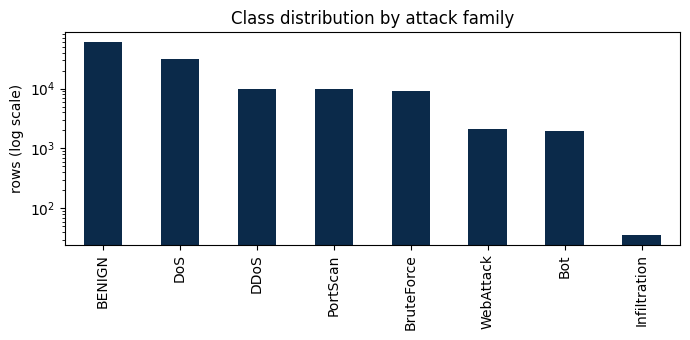

In [ ]:
present_days = [d for d in DAYS if d in data["day"].unique()]
summary = pd.crosstab(data["family"], data["day"])[present_days]
summary["total"] = summary.sum(axis=1)
display(summary)
save_table(summary, "table1_dataset_summary")

fam_counts = data["family"].value_counts()
fig, ax = plt.subplots(figsize=(7, 3.5))
fam_counts.plot.bar(ax=ax, color="#0b2a4a")
ax.set_yscale("log"); ax.set_ylabel("rows (log scale)"); ax.set_xlabel("")
ax.set_title("Class distribution by attack family")
save_fig("fig1_family_counts")

In [ ]:
feature_cols = [c for c in data.columns if c not in ["Label", "day", "family", "y"]]
print(len(feature_cols), "numeric features")

skew = data[feature_cols].skew().sort_values(ascending=False)
print("\nMost skewed features:")
print(skew.head(5).round(1).to_string())


port_share = data.groupby("family")["Destination Port"].agg(lambda s: s.value_counts(normalize=True).iloc[0]).round(3)
port_df = port_share.to_frame("share_on_top_port")
display(port_df)
save_table(port_df, "table2_destination_port_concentration")

77 numeric features

Most skewed features:
Fwd URG Flags                  352.000000
CWE Flag Count                 352.000000
act_data_pkt_fwd               345.600006
Total Length of Bwd Packets    344.899994
Subflow Bwd Bytes              344.899994


,share_on_top_port
family,
BENIGN,0.422
Bot,0.640
BruteForce,0.648
DDoS,1.000
DoS,1.000
Infiltration,1.000
PortScan,0.004
WebAttack,1.000


## 5. Folds, models and helper functions


In [ ]:
X_raw = data[feature_cols]
y = data["y"].values

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(skf.split(X_raw, y))

MODELS = {
    "LogReg":       lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=200)),
    "RandomForest": lambda: RandomForestClassifier(n_estimators=50, n_jobs=-1, random_state=SEED),
    "LightGBM":     lambda: LGBMClassifier(n_estimators=200, random_state=SEED, verbose=-1),
}

def evaluate(model, X_tr, y_tr, X_te, y_te):
    t0 = time.time(); model.fit(X_tr, y_tr); fit_sec = time.time() - t0
    t0 = time.time(); p = model.predict_proba(X_te)[:, 1]; pred_sec = time.time() - t0
    pred = (p >= 0.5).astype(int)
    fpr, tpr, _ = roc_curve(y_te, p)
    scores = {"auc": roc_auc_score(y_te, p),
              "pr_auc": average_precision_score(y_te, p),
              "tpr_at_1pct_fpr": float(np.interp(0.01, fpr, tpr)),
              "precision": precision_score(y_te, pred, zero_division=0),
              "recall": recall_score(y_te, pred, zero_division=0),
              "f1": f1_score(y_te, pred, zero_division=0),
              "fit_sec": fit_sec, "predict_sec": pred_sec}
    return scores, p

def cv_eval(model_fn, X):
    rows = []
    for i, (tr, te) in enumerate(folds):
        scores, _ = evaluate(model_fn(), X.iloc[tr], y[tr], X.iloc[te], y[te])
        scores["fold"] = i + 1
        rows.append(scores)
    return pd.DataFrame(rows)

METRICS = ["auc", "pr_auc", "tpr_at_1pct_fpr", "precision", "recall", "f1", "fit_sec", "predict_sec"]

## 6. Experiment A: random 5-fold cross-validation

In [ ]:
cv_results = {name: cv_eval(fn, X_raw) for name, fn in MODELS.items()}

rows = []
for name, r in cv_results.items():
    row = {"exp": "A_random_cv", "model": name, "setting": "raw", "auc_std": r["auc"].std()}
    row.update({m: r[m].mean() for m in METRICS})
    rows.append(row)
results_A = pd.DataFrame(rows)
display(results_A.round(4))

fold_table = pd.concat({k: v.set_index("fold")["auc"] for k, v in cv_results.items()}, axis=1)
display(fold_table.round(4))
save_table(fold_table, "table3_fold_auc_random_cv")

,exp,model,setting,auc_std,auc,pr_auc,tpr_at_1pct_fpr,precision,recall,f1,fit_sec,predict_sec
0,A_random_cv,LogReg,raw,0.0018,0.9780,0.9777,0.5962,0.9178,0.9603,0.9385,9.4432,0.0442
1,A_random_cv,RandomForest,raw,0.0001,0.9996,0.9994,0.9996,0.9984,0.9973,0.9979,11.6461,0.1124
2,A_random_cv,LightGBM,raw,0.0000,0.9999,0.9999,0.9999,0.9983,0.9992,0.9988,7.0133,0.3631


,LogReg,RandomForest,LightGBM
fold,,,
1,0.9774,0.9995,0.9999
2,0.9768,0.9998,1.0000
3,0.9808,0.9995,0.9999
4,0.9765,0.9997,1.0000
5,0.9786,0.9997,0.9999


## 7. Feature study


In [ ]:
exp_log = []
def log_experiment(name, model, hypothesis, change, base, new):
    wins = int((new > base).sum())
    gain = float((new - base).mean())
    decision = "real gain" if wins == N_FOLDS else "not a real gain"
    exp_log.append({"id": name, "model": model, "hypothesis": hypothesis, "change": change,
                    "folds_better": f"{wins} of {N_FOLDS}", "avg_auc_change": round(gain, 5), "decision": decision})


skewed = [c for c in feature_cols if data[c].min() >= 0 and data[c].skew() > 10]
X_log = X_raw.copy()
X_log[skewed] = np.log1p(X_raw[skewed])
new = cv_eval(MODELS["LogReg"], X_log)
log_experiment("H1", "LogReg", "Heavy-tailed counts hurt a linear model",
               f"log1p on {len(skewed)} skewed columns", cv_results["LogReg"]["auc"].values, new["auc"].values)

flag_cols = ["FIN Flag Count", "SYN Flag Count", "RST Flag Count", "PSH Flag Count", "ACK Flag Count", "URG Flag Count"]

def add_features(df):
    out = df.copy()
    total_pkts = out["Total Fwd Packets"] + out["Total Backward Packets"]
    out["Fwd_Bwd_Pkt_Ratio"] = out["Total Fwd Packets"] / (out["Total Backward Packets"] + 1)
    out["Bytes_per_Pkt"] = (out["Total Length of Fwd Packets"] + out["Total Length of Bwd Packets"]) / (total_pkts + 1)
    out["Flag_Sum"] = out[flag_cols].sum(axis=1)
    out["Log_Flow_Duration"] = np.log1p(out["Flow Duration"].clip(lower=0))
    return out

X_fe = add_features(X_raw)
new = cv_eval(MODELS["LightGBM"], X_fe)
log_experiment("H2", "LightGBM", "Attacks show unusual packet/byte/flag patterns",
               "add 4 engineered features", cv_results["LightGBM"]["auc"].values, new["auc"].values)


new = cv_eval(MODELS["LightGBM"], X_raw.drop(columns=["Destination Port"]))
log_experiment("H3", "LightGBM", "Destination Port is a shortcut random CV cannot see",
               "drop Destination Port", cv_results["LightGBM"]["auc"].values, new["auc"].values)

exp_log_df = pd.DataFrame(exp_log)
display(exp_log_df)
save_table(exp_log_df, "table4_feature_study", index=False)

,id,model,hypothesis,change,folds_better,avg_auc_change,decision
0,H1,LogReg,Heavy-tailed counts hurt a linear model,log1p on 22 skewed columns,0 of 5,-0.00153,not a real gain
1,H2,LightGBM,Attacks show unusual packet/byte/flag patterns,add 4 engineered features,2 of 5,-0.00000,not a real gain
2,H3,LightGBM,Destination Port is a shortcut random CV canno...,drop Destination Port,0 of 5,-0.00004,not a real gain


## 8. Experiment B: train on Monday-Wednesday, test on Thursday-Friday


In [ ]:
settings = {
    "raw": X_raw,
    "raw - Destination Port": X_raw.drop(columns=["Destination Port"]),
    "engineered": X_fe,
}
def models_for(setting):
    return {"LightGBM": MODELS["LightGBM"]} if setting == "engineered" else MODELS

train_day = data["day"].isin(["monday", "tuesday", "wednesday"]).values
print("train rows:", int(train_day.sum()), "| attack share:", round(y[train_day].mean(), 3))
print("test rows: ", int((~train_day).sum()), "| attack share:", round(y[~train_day].mean(), 3))

rows, preds_B = [], {}
for setting, X in settings.items():
    for name, fn in models_for(setting).items():
        scores, p = evaluate(fn(), X[train_day], y[train_day], X[~train_day], y[~train_day])
        preds_B[(setting, name)] = p
        row = {"exp": "B_train_MonWed_test_ThuFri", "model": name, "setting": setting, "auc_std": np.nan}
        row.update(scores)
        rows.append(row)
        print(f"{setting:25s} {name:13s} AUC = {scores['auc']:.4f}")
results_B = pd.DataFrame(rows)

train rows: 76990 | attack share: 0.517
test rows:  46911 | attack share: 0.514
raw                       LogReg        AUC = 0.7515
raw                       RandomForest  AUC = 0.8469
raw                       LightGBM      AUC = 0.7405
raw - Destination Port    LogReg        AUC = 0.9226
raw - Destination Port    RandomForest  AUC = 0.8314
raw - Destination Port    LightGBM      AUC = 0.8955
engineered                LightGBM      AUC = 0.7323


## 9. Experiment C: leave one attack family out (zero-day test)


In [ ]:
rng = np.random.RandomState(SEED)
benign_test = ((data["family"] == "BENIGN") & (rng.rand(len(data)) < 0.3)).values
families = [f for f in data["family"].unique() if f != "BENIGN" and (data["family"] == f).sum() >= 100]
skipped = [f for f in data["family"].unique() if f != "BENIGN" and f not in families]
print("families tested:", families)
print("skipped (fewer than 100 rows):", skipped)

rows, preds_C = [], {}
for fam in families:
    is_fam = (data["family"] == fam).values
    test_mask = is_fam | benign_test
    train_mask = ~is_fam & ~benign_test
    for setting, X in settings.items():
        for name, fn in models_for(setting).items():
            scores, p = evaluate(fn(), X[train_mask], y[train_mask], X[test_mask], y[test_mask])
            if name == "LightGBM" and setting == "raw":
                preds_C[fam] = (y[test_mask], p)
            row = {"exp": "C_unseen_family", "family": fam, "model": name, "setting": setting}
            row.update(scores)
            rows.append(row)
    print("done:", fam)
results_C = pd.DataFrame(rows)

families tested: ['DDoS', 'BruteForce', 'DoS', 'WebAttack', 'PortScan', 'Bot']
skipped (fewer than 100 rows): ['Infiltration']
done: DDoS
done: BruteForce
done: DoS
done: WebAttack
done: PortScan
done: Bot


## 10. Result tables

In [ ]:
all_results = pd.concat([results_A, results_B, results_C], ignore_index=True)
save_table(all_results.round(5), "results_all", index=False)


gap = pd.DataFrame({
    "A_random_cv_AUC": results_A.set_index("model")["auc"],
    "B_new_days_AUC": results_B[results_B["setting"] == "raw"].set_index("model")["auc"]})
gap["gap"] = gap["A_random_cv_AUC"] - gap["B_new_days_AUC"]
print("Table 5. Generalization gap (raw features)")
display(gap.round(4)); save_table(gap.round(4), "table5_generalization_gap")


t6 = results_C.pivot_table(index=["setting", "model"], columns="family", values="auc")
t6["mean"] = t6.mean(axis=1)
print("Table 6. AUC for each unseen attack family")
display(t6.round(3)); save_table(t6.round(4), "table6_unseen_family_auc")


port = pd.concat([results_B[["model", "setting", "auc"]].assign(test="B_new_days"),
                  results_C.groupby(["model", "setting"], as_index=False)["auc"].mean().assign(test="C_unseen_mean")])
t7 = port[port["setting"].isin(["raw", "raw - Destination Port"])].pivot_table(
        index=["test", "model"], columns="setting", values="auc")
t7["change_without_port"] = t7["raw - Destination Port"] - t7["raw"]
print("Table 7. Effect of removing Destination Port")
display(t7.round(4)); save_table(t7.round(4), "table7_port_effect")


t8 = results_B[results_B["setting"] == "raw"].set_index("model")[["fit_sec", "predict_sec", "precision", "recall", "f1"]]
print("Table 8. Time and threshold-0.5 metrics on new days (raw)")
display(t8.round(3)); save_table(t8.round(4), "table8_cost_and_f1_new_days")

Table 5. Generalization gap (raw features)


,A_random_cv_AUC,B_new_days_AUC,gap
model,,,
LogReg,0.9780,0.7515,0.2265
RandomForest,0.9996,0.8469,0.1527
LightGBM,0.9999,0.7405,0.2595


Table 6. AUC for each unseen attack family


family                                 Bot  BruteForce   DDoS    DoS  \
setting                model                                           
engineered             LightGBM      0.733       0.978  0.994  0.986   
raw                    LightGBM      0.864       0.992  0.990  0.987   
                       LogReg        0.832       0.790  0.953  0.598   
                       RandomForest  0.656       0.959  0.993  0.936   
raw - Destination Port LightGBM      0.874       0.932  0.987  0.960   
                       LogReg        0.818       0.778  0.941  0.618   
                       RandomForest  0.617       0.945  0.967  0.928   

family                               PortScan  WebAttack   mean  
setting                model                                     
engineered             LightGBM         0.881      0.998  0.928  
raw                    LightGBM         0.897      0.998  0.955  
                       LogReg           0.920      0.858  0.825  
                       RandomForest     0.798      0.996  0.890  
raw - Destination Port LightGBM         0.894      0.995  0.940  
                       LogReg           0.942      0.848  0.824  
                       RandomForest     0.709      0.979  0.857

Table 7. Effect of removing Destination Port


setting                        raw  raw - Destination Port  \
test          model                                          
B_new_days    LightGBM      0.7405                  0.8955   
              LogReg        0.7515                  0.9226   
              RandomForest  0.8469                  0.8314   
C_unseen_mean LightGBM      0.9546                  0.9403   
              LogReg        0.8252                  0.8241   
              RandomForest  0.8896                  0.8573   

setting                     change_without_port  
test          model                              
B_new_days    LightGBM                   0.1550  
              LogReg                     0.1711  
              RandomForest              -0.0155  
C_unseen_mean LightGBM                  -0.0143  
              LogReg                    -0.0011  
              RandomForest              -0.0324

Table 8. Time and threshold-0.5 metrics on new days (raw)


,fit_sec,predict_sec,precision,recall,f1
model,,,,,
LogReg,4.675,0.131,0.923,0.407,0.565
RandomForest,9.784,0.310,0.996,0.286,0.445
LightGBM,6.497,0.596,0.999,0.362,0.532


## 11. Which attacks are missed on new days?


,model,family,n_flows,detected_at_1pct_fpr,detected_at_thr_0.5
0,LogReg,Bot,1948,0.023,0.023
1,LogReg,DDoS,10000,0.631,0.846
2,LogReg,Infiltration,36,0.056,0.111
3,LogReg,PortScan,10000,0.051,0.130
4,LogReg,WebAttack,2143,0.002,0.003
5,RandomForest,Bot,1948,0.000,0.000
6,RandomForest,DDoS,10000,0.892,0.631
7,RandomForest,Infiltration,36,0.028,0.000
8,RandomForest,PortScan,10000,0.041,0.003
9,RandomForest,WebAttack,2143,0.999,0.262


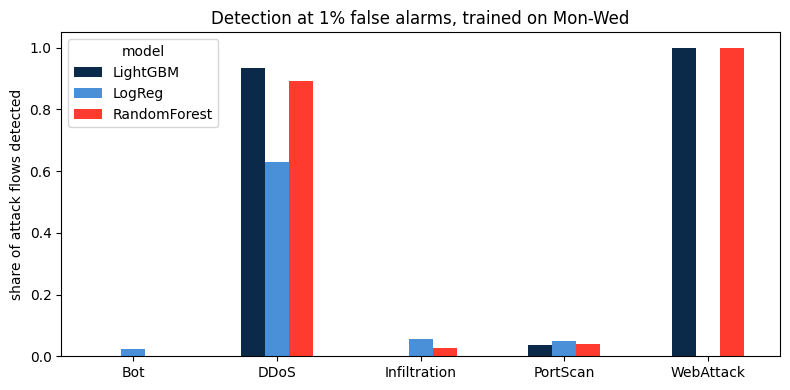

Confusion matrix, LightGBM, new days, threshold 0.5


,pred BENIGN,pred ATTACK
true BENIGN,22774,10
true ATTACK,15384,8743


In [ ]:
test_family = data.loc[~train_day, "family"].values
y_test = y[~train_day]

rows = []
for name in MODELS:
    p = preds_B[("raw", name)]
    thr = np.quantile(p[y_test == 0], 0.99)
    for fam in sorted(set(test_family) - {"BENIGN"}):
        m = test_family == fam
        rows.append({"model": name, "family": fam, "n_flows": int(m.sum()),
                     "detected_at_1pct_fpr": float((p[m] > thr).mean()),
                     "detected_at_thr_0.5": float((p[m] >= 0.5).mean())})
recall_fam = pd.DataFrame(rows)
display(recall_fam.round(3))
save_table(recall_fam.round(4), "table9_detection_by_family_new_days", index=False)

pv = recall_fam.pivot(index="family", columns="model", values="detected_at_1pct_fpr")
ax = pv.plot.bar(figsize=(8, 4), color=["#0b2a4a", "#4a90d9", "#ff3b30"])
ax.set_ylabel("share of attack flows detected"); ax.set_xlabel(""); ax.set_ylim(0, 1.05)
ax.set_title("Detection at 1% false alarms, trained on Mon-Wed"); plt.xticks(rotation=0)
save_fig("fig2_detection_by_family")

cm = confusion_matrix(y_test, (preds_B[("raw", "LightGBM")] >= 0.5).astype(int))
cm_df = pd.DataFrame(cm, index=["true BENIGN", "true ATTACK"], columns=["pred BENIGN", "pred ATTACK"])
print("Confusion matrix, LightGBM, new days, threshold 0.5")
display(cm_df); save_table(cm_df, "table10_confusion_matrix_lightgbm_new_days")

## 12. Figures

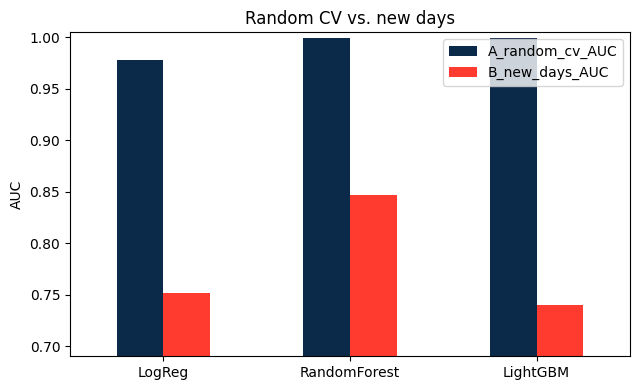

In [ ]:
# generalization gap
ax = gap[["A_random_cv_AUC", "B_new_days_AUC"]].plot.bar(figsize=(6.5, 4), color=["#0b2a4a", "#ff3b30"])
ax.set_ylim(max(0.5, float(gap[["A_random_cv_AUC", "B_new_days_AUC"]].min().min()) - 0.05), 1.005)
ax.set_ylabel("AUC"); ax.set_xlabel(""); ax.set_title("Random CV vs. new days"); plt.xticks(rotation=0)
save_fig("fig3_generalization_gap")

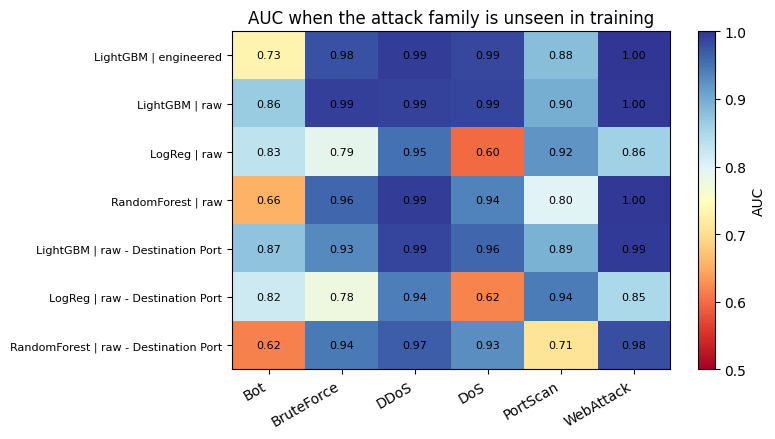

In [ ]:
# AUC per unseen attack family
hm = results_C.pivot_table(index=["setting", "model"], columns="family", values="auc")
fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(hm.values, cmap="RdYlBu", vmin=0.5, vmax=1.0, aspect="auto")
ax.set_xticks(range(hm.shape[1])); ax.set_xticklabels(hm.columns, rotation=30, ha="right")
ax.set_yticks(range(hm.shape[0])); ax.set_yticklabels([f"{m} | {s}" for s, m in hm.index], fontsize=8)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        ax.text(j, i, f"{hm.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="AUC"); ax.set_title("AUC when the attack family is unseen in training")
save_fig("fig4_unseen_family_heatmap")

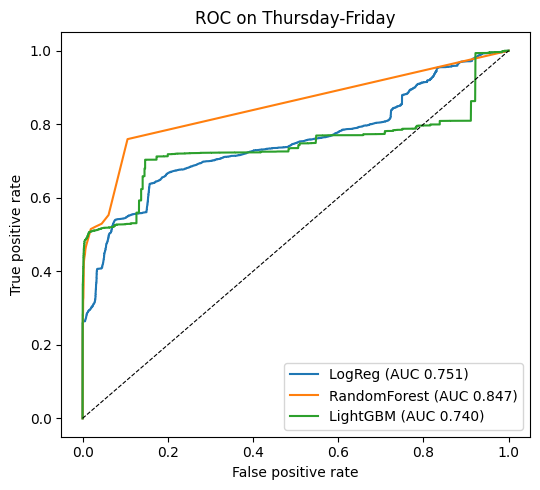

In [ ]:
# ROC curves on new days
fig, ax = plt.subplots(figsize=(5.5, 5))
for name in MODELS:
    p = preds_B[("raw", name)]
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.legend()
ax.set_title("ROC on Thursday-Friday")
save_fig("fig5_roc_new_days")

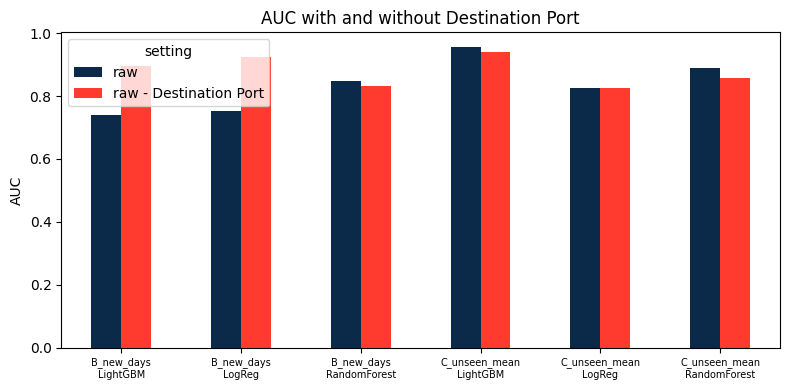

In [ ]:
# effect of the Destination Port feature
t7_plot = t7[["raw", "raw - Destination Port"]]
ax = t7_plot.plot.bar(figsize=(8, 4), color=["#0b2a4a", "#ff3b30"])
ax.set_ylabel("AUC"); ax.set_xlabel(""); ax.set_title("AUC with and without Destination Port")
ax.set_xticklabels([f"{a}\n{b}" for a, b in t7_plot.index], rotation=0, fontsize=7)
save_fig("fig6_port_effect")

Spearman rank correlation of feature importance (A vs B): 0.767


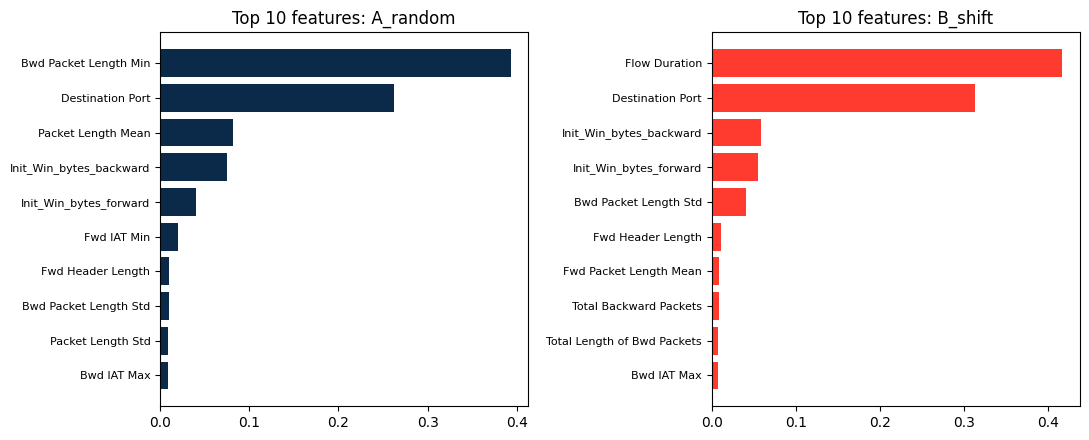

In [ ]:
# does the model use the same features under random CV and under shift?
tr0, _ = folds[0]
m_a = LGBMClassifier(n_estimators=200, random_state=SEED, verbose=-1, importance_type="gain").fit(X_raw.iloc[tr0], y[tr0])
m_b = LGBMClassifier(n_estimators=200, random_state=SEED, verbose=-1, importance_type="gain").fit(X_raw[train_day], y[train_day])
imp = pd.DataFrame({"feature": feature_cols,
                    "A_random": m_a.feature_importances_ / m_a.feature_importances_.sum(),
                    "B_shift": m_b.feature_importances_ / m_b.feature_importances_.sum()})
rho = imp[["A_random", "B_shift"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman rank correlation of feature importance (A vs B): {rho:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col, color in zip(axes, ["A_random", "B_shift"], ["#0b2a4a", "#ff3b30"]):
    top = imp.nlargest(10, col).iloc[::-1]
    ax.barh(top["feature"], top[col], color=color)
    ax.set_title(f"Top 10 features: {col}"); ax.tick_params(axis="y", labelsize=8)
save_fig("fig7_importance_drift")
save_table(imp.sort_values("A_random", ascending=False).round(5), "table11_feature_importance", index=False)

## 13. Uncertainty: bootstrap 95% confidence intervals


In [ ]:
def bootstrap_auc(y_true, p, n_boot=200, seed=SEED):
    rng = np.random.RandomState(seed)
    aucs = []
    for _ in range(n_boot):
        idx = rng.randint(0, len(y_true), len(y_true))
        if y_true[idx].min() == y_true[idx].max():
            continue
        aucs.append(roc_auc_score(y_true[idx], p[idx]))
    return np.percentile(aucs, 2.5), np.percentile(aucs, 97.5)

rows = []
for (setting, name), p in preds_B.items():
    lo, hi = bootstrap_auc(y_test, p)
    rows.append({"test": "B_new_days", "model": name, "setting": setting,
                 "AUC": roc_auc_score(y_test, p), "ci_low": lo, "ci_high": hi})
for fam, (yt, p) in preds_C.items():
    lo, hi = bootstrap_auc(yt, p)
    rows.append({"test": f"C_unseen_{fam}", "model": "LightGBM", "setting": "raw",
                 "AUC": roc_auc_score(yt, p), "ci_low": lo, "ci_high": hi})
ci_table = pd.DataFrame(rows)
display(ci_table.round(4))
save_table(ci_table.round(4), "table12_bootstrap_ci", index=False)

,test,model,setting,AUC,ci_low,ci_high
0,B_new_days,LogReg,raw,0.7515,0.7472,0.7559
1,B_new_days,RandomForest,raw,0.8469,0.8444,0.8505
2,B_new_days,LightGBM,raw,0.7405,0.7358,0.7465
3,B_new_days,LogReg,raw - Destination Port,0.9226,0.9205,0.9251
4,B_new_days,RandomForest,raw - Destination Port,0.8314,0.8285,0.8346
5,B_new_days,LightGBM,raw - Destination Port,0.8955,0.8930,0.8983
6,B_new_days,LightGBM,engineered,0.7323,0.7282,0.7379
7,C_unseen_DDoS,LightGBM,raw,0.9898,0.9889,0.9907
8,C_unseen_BruteForce,LightGBM,raw,0.9920,0.9909,0.9931
9,C_unseen_DoS,LightGBM,raw,0.9873,0.9865,0.9880


## 14. Key numbers (generated from the results, copy into the paper)

In [ ]:
lines = []
lines.append(f"Rows used: {len(data):,} ({data['y'].mean():.1%} attacks). Cleaning removed {clean_log['rows with NaN or inf (dropped)']:,} NaN/inf rows and {clean_log['duplicate rows (dropped)']:,} duplicates from {clean_log['raw rows']:,} raw rows.")
for m in gap.index:
    lines.append(f"{m}: random-CV AUC {gap.loc[m, 'A_random_cv_AUC']:.4f}, new-days AUC {gap.loc[m, 'B_new_days_AUC']:.4f}, gap {gap.loc[m, 'gap']:+.4f}.")
cl = results_C[(results_C["setting"] == "raw") & (results_C["model"] == "LightGBM")].sort_values("auc")
lines.append(f"LightGBM, unseen family: worst = {cl.iloc[0]['family']} (AUC {cl.iloc[0]['auc']:.3f}), best = {cl.iloc[-1]['family']} (AUC {cl.iloc[-1]['auc']:.3f}).")
pb = t7.loc["B_new_days", "change_without_port"]
lines.append("AUC change on new days when Destination Port is removed: " + ", ".join(f"{m} {v:+.4f}" for m, v in pb.items()) + ".")
lines.append(f"Feature-importance rank correlation, random CV vs new days (LightGBM): {rho:.3f}.")
weak = recall_fam.sort_values("detected_at_1pct_fpr").head(3)
lines.append("Lowest detection at 1% false alarms on new days: " + "; ".join(f"{r.model}/{r.family} {r.detected_at_1pct_fpr:.2f}" for r in weak.itertuples()) + ".")
for l in lines: print("-", l)
open(f"{OUT}/key_numbers.txt", "w").write("\n".join(lines))

- Rows used: 123,901 (51.6% attacks). Cleaning removed 2,867 NaN/inf rows and 307,078 duplicates from 2,830,743 raw rows.
- LogReg: random-CV AUC 0.9780, new-days AUC 0.7515, gap +0.2265.
- RandomForest: random-CV AUC 0.9996, new-days AUC 0.8469, gap +0.1527.
- LightGBM: random-CV AUC 0.9999, new-days AUC 0.7405, gap +0.2595.
- LightGBM, unseen family: worst = Bot (AUC 0.864), best = WebAttack (AUC 0.998).
- AUC change on new days when Destination Port is removed: LightGBM +0.1550, LogReg +0.1711, RandomForest -0.0155.
- Feature-importance rank correlation, random CV vs new days (LightGBM): 0.767.
- Lowest detection at 1% false alarms on new days: RandomForest/Bot 0.00; LightGBM/Bot 0.00; LightGBM/Infiltration 0.00.


709

## 15. Save everything for the paper

In [ ]:
config = {"FAST_MODE": FAST_MODE, "SEED": SEED, "N_FOLDS": N_FOLDS, "BENIGN_CAP": BENIGN_CAP, "ATTACK_CAP": ATTACK_CAP,
          "rows_used": int(len(data)), "n_features": len(feature_cols), "files": [os.path.basename(f) for f in files],
          "python": platform.python_version(), "sklearn": sklearn.__version__, "lightgbm": lightgbm.__version__}
json.dump(config, open(f"{OUT}/run_config.json", "w"), indent=2)

shutil.make_archive("paper_outputs", "zip", OUT)
print("Saved paper_outputs.zip with:", len(os.listdir(f"{OUT}/tables")), "tables and",
      len(os.listdir(f"{OUT}/figures")), "figures")
if FAST_MODE:
    print("\nFAST_MODE is on: these numbers are for testing. Set FAST_MODE = False for the paper.")

Saved paper_outputs.zip with: 14 tables and 7 figures

FAST_MODE is on: these numbers are for testing. Set FAST_MODE = False for the paper.
